# 02 数据质量检查（MySQL + Python 可视化）

**数据源**：MySQL `olist` 库
**分析逻辑**：执行 `analysis_code/01_data_quality.sql`（8 条检查）
**目标**：在正式分析前，把「数据能不能用、哪里有坑」说清楚。这是分析可信度的地基。


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 找到项目根（含 analysis_code/ 的目录），兼容从 notebooks/ 或项目根启动
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_code").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))
import db

# 先设 seaborn 主题，再设中文字体（顺序不能反）
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

print("project root:", PROJECT_ROOT)
print("sql dir:", db.SQL_DIR)

project root: C:\Users\iiLI\Desktop\1
sql dir: C:\Users\iiLI\Desktop\1\analysis_code


## 1. 执行 SQL

In [2]:
results = db.run_sql_file(db.SQL_DIR / "01_data_quality.sql")
(
    tbl_counts,
    null_rates,
    dup_reviews,
    category_missing,
    time_errors,
    delivery_anomaly,
    canceled_review,
    geo_dedup,
) = results

print("返回结果数:", len(results))
tbl_counts

返回结果数: 8


,tbl,row_cnt
0,order,99441
1,customers,99441
2,order_items,112650
3,order_payments,103886
4,order_reviews,99223
5,products,32951
6,sellers,3095
7,product_category_name_translation,71
8,geolocation,1000163


## 2. 九张表行数

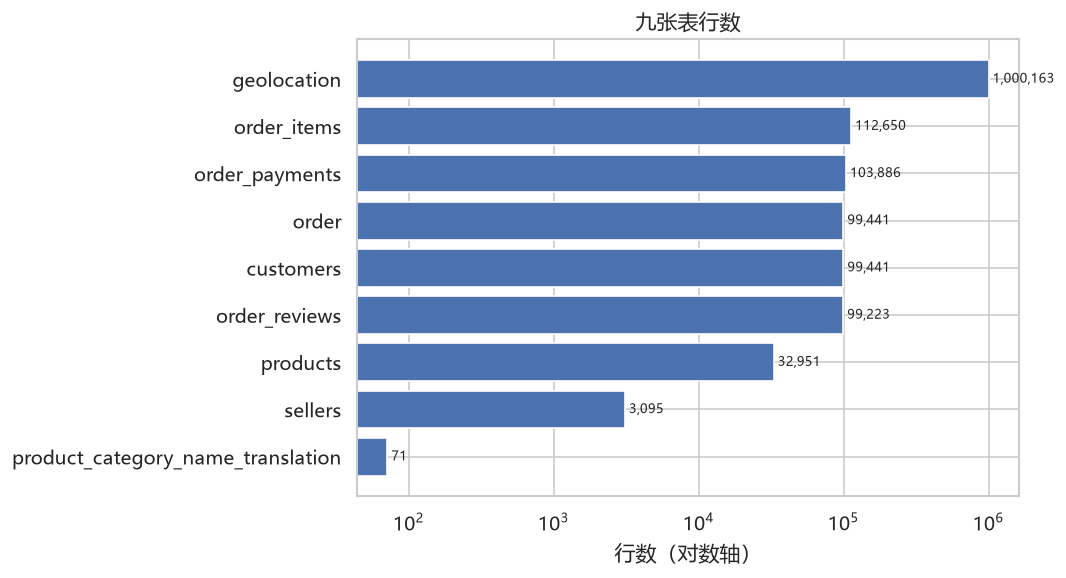

In [3]:
counts = tbl_counts.sort_values("row_cnt")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(counts["tbl"], counts["row_cnt"], color="#4C72B0")
ax.set_xscale("log")
for bar, v in zip(ax.patches, counts["row_cnt"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f" {int(v):,}", va="center", fontsize=8)
ax.set_xlabel("行数（对数轴）")
ax.set_title("九张表行数")
plt.tight_layout()
plt.show()

### 观察
- `geolocation` 是 100 万行级别，远大于其他表；`order_reviews` 在 MySQL 里是 99,223 行，但原始 CSV 是 99,224 行，**差 1 行**。
- 差 1 行可能与导入时评论内容含换行、`LOAD DATA` 解析异常有关（待核实）（不影响整体分析，但要在文档里诚实说明）。


## 3. 关键列空值率

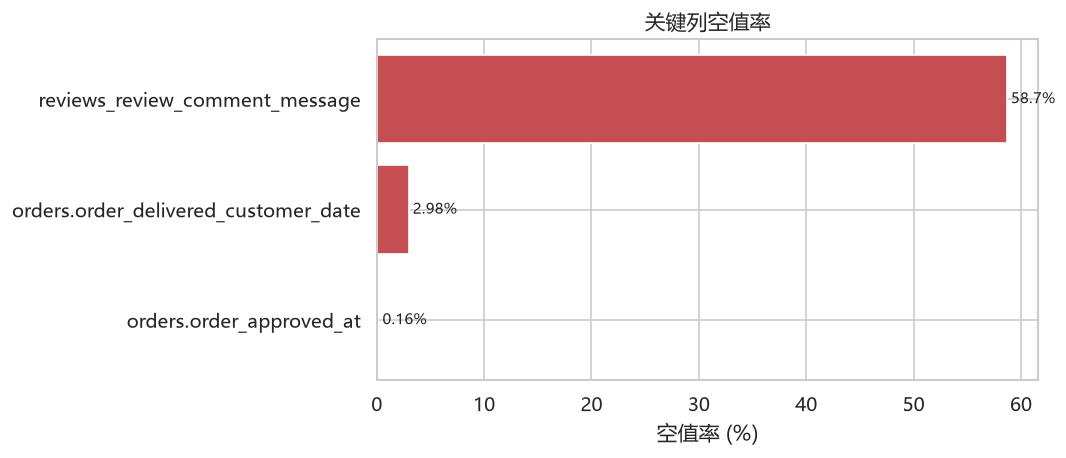

In [4]:
nr = null_rates.sort_values("pct_null")

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(nr["tbl"], nr["pct_null"], color="#C44E52")
for bar, v in zip(ax.patches, nr["pct_null"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f" {v}%", va="center", fontsize=9)
ax.set_xlabel("空值率 (%)")
ax.set_title("关键列空值率")
plt.tight_layout()
plt.show()

### 观察
- `order_delivered_customer_date` 缺失 2.98%，对应「未送达/取消」订单，物流分析时必须过滤。
- `review_comment_message` 缺失 58.70%，说明**评价内容**大量为空——但 `review_score`（评分）仍有值，所以做评分分析没问题，做文本分析要单独说明样本偏差。
- `order_approved_at` 缺失 0.16%，影响很小。


## 4. 结构性问题（重复评价 / 品类缺失 / 时间逻辑 / 配送异常 / 取消带评价）

In [5]:
checks = pd.DataFrame([
    {"检查项": "同一订单多条评价", "数量": int(dup_reviews.iloc[0, 0])},
    {"检查项": "品类为空的商品", "数量": int(category_missing["null_category_products"].iloc[0])},
    {"检查项": "品类无法翻译", "数量": int(category_missing["untranslation_products"].iloc[0])},
    {"检查项": "批准晚于承运", "数量": int(time_errors["approved_after_carried"].iloc[0])},
    {"检查项": "承运晚于签收", "数量": int(time_errors["carried_after_deliverd"].iloc[0])},
    {"检查项": "购买晚于批准", "数量": int(time_errors["purchase_after_approved"].iloc[0])},
    {"检查项": "配送天数为负", "数量": int(delivery_anomaly["negative_delivery_days"].iloc[0])},
    {"检查项": "配送 > 60 天", "数量": int(delivery_anomaly["over_60_delivery_days"].iloc[0])},
    {"检查项": "取消订单带评价", "数量": int(canceled_review.iloc[0, 0])},
])
checks

,检查项,数量
0,同一订单多条评价,547
1,品类为空的商品,610
2,品类无法翻译,13
3,批准晚于承运,1358
4,承运晚于签收,23
5,购买晚于批准,0
6,配送天数为负,0
7,配送 > 60 天,298
8,取消订单带评价,605


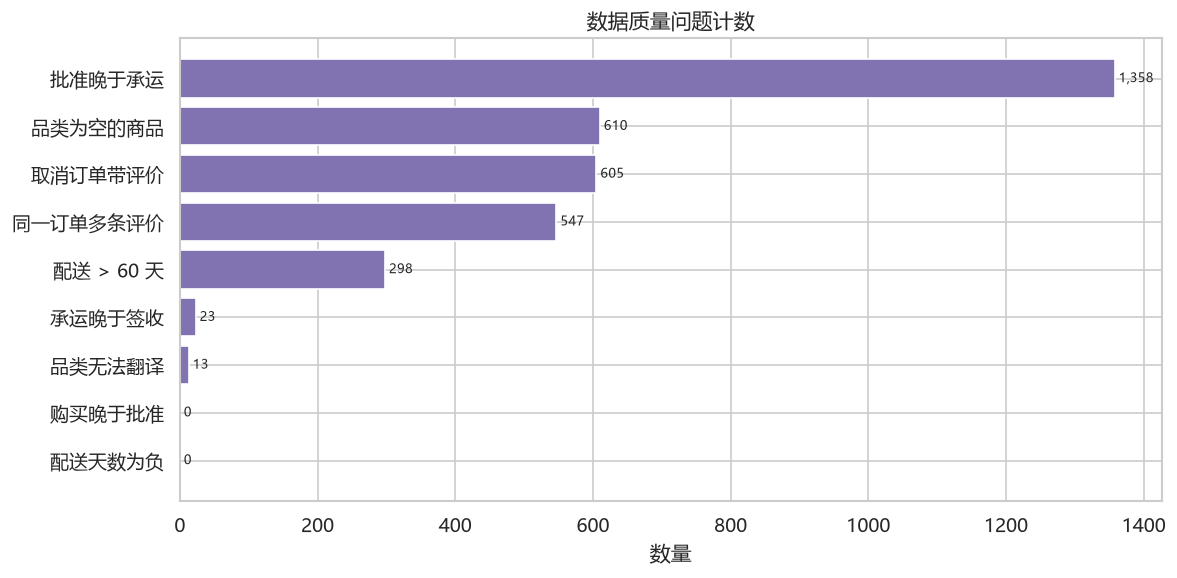

In [6]:
c = checks.sort_values("数量")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(c["检查项"], c["数量"], color="#8172B2")
for bar, v in zip(ax.patches, c["数量"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f" {int(v):,}", va="center", fontsize=8)
ax.set_xlabel("数量")
ax.set_title("数据质量问题计数")
plt.tight_layout()
plt.show()

### 观察
- 「同一订单多条评价」有几百条：SQL 里 `02_base_view` 已按订单去重（保留最早一条），所以分析不会重复计数。
- 「批准晚于承运」有上千条，属于时间逻辑异常，物流分段分析时要留意。
- 品类为空 610 个商品、无法翻译 13 个，`04` 里已用 `unknown` 兜底。
- 取消订单带评价 605 条：说明评价不一定代表「成功交易」，做评分分析时要知道这一点。


## 5. geolocation 去重

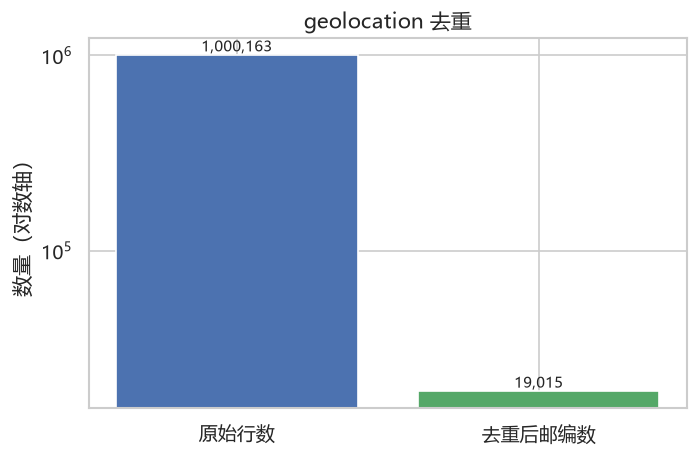

In [7]:
raw_n = int(geo_dedup["raw_rows"].iloc[0])
uniq_n = int(geo_dedup["unique_zips"].iloc[0])

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["原始行数", "去重后邮编数"], [raw_n, uniq_n], color=["#4C72B0", "#55A868"])
ax.set_yscale("log")
for bar, v in zip(ax.patches, [raw_n, uniq_n]):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("数量（对数轴）")
ax.set_title("geolocation 去重")
plt.tight_layout()
plt.show()

### 观察
- 100 万个坐标点对应 **19,015** 个邮编，同一邮编有大量重复坐标。
- 如果要用地图，应该先按邮编聚合（取经纬度均值），否则会重复计数。
